multiple x and 1 y


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [9]:
data=pd.read_csv("Advertising.csv")

In [11]:
data.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


y=sales
x=tv,radio,newspaper

In [16]:
data.describe()

,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [20]:
data.shape

(200, 5)

In [22]:
data.size

1000

In [24]:
data.dtypes

Unnamed: 0      int64
TV            float64
radio         float64
newspaper     float64
sales         float64
dtype: object

In [26]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [28]:
data.isna().sum()  #check null value

Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64

In [32]:
data.duplicated().sum()

0

In [50]:
core=data.corr()

In [52]:
core

,Unnamed: 0,TV,radio,newspaper,sales
Unnamed: 0,1.000000,0.017715,-0.110680,-0.154944,-0.051616
TV,0.017715,1.000000,0.054809,0.056648,0.782224
radio,-0.110680,0.054809,1.000000,0.354104,0.576223
newspaper,-0.154944,0.056648,0.354104,1.000000,0.228299
sales,-0.051616,0.782224,0.576223,0.228299,1.000000


[]

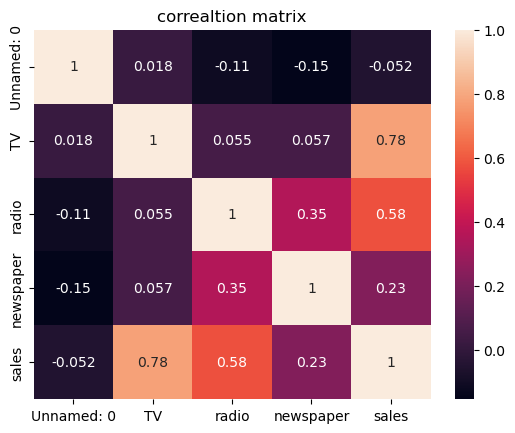

In [56]:
sns.heatmap(core,annot=True)
plt.title("correaltion matrix")
plt.plot()

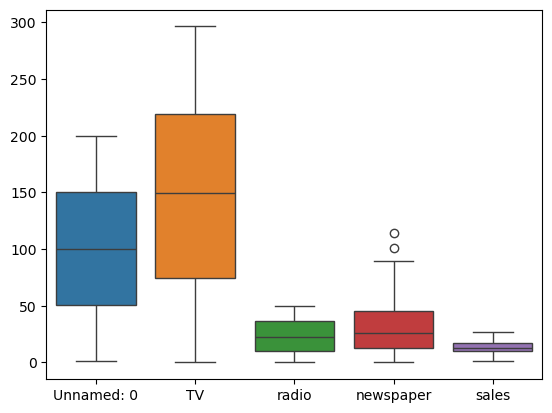

In [59]:
sns.boxplot(data=data)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

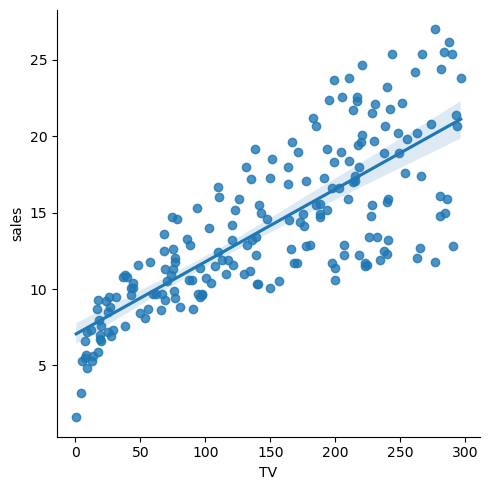

In [61]:
sns.lmplot(x='TV',y='sales',data=data)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

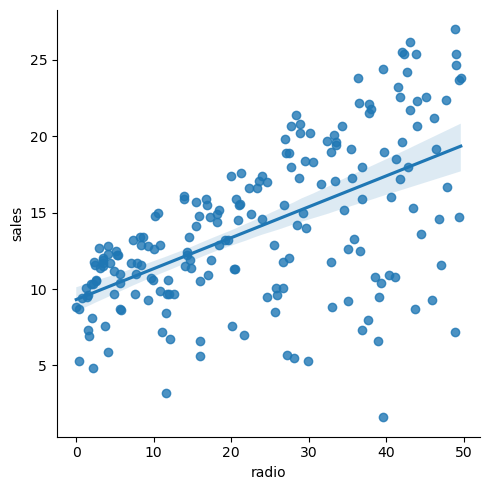

In [63]:
sns.lmplot(x='radio',y='sales',data=data)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

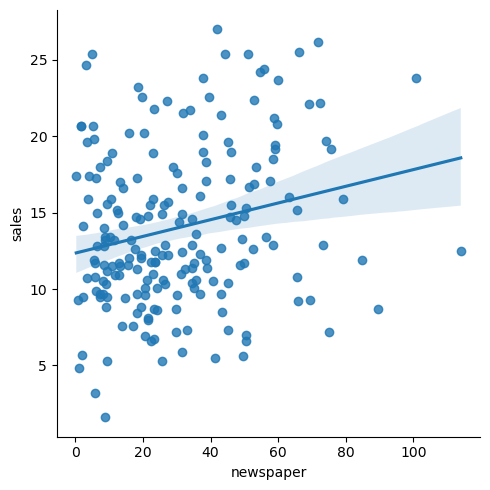

In [65]:
sns.lmplot(x='newspaper',y='sales',data=data)
plt.show

In [73]:
#splitting data into x and y

x=data[['TV','radio','newspaper']]
y=data['sales']

In [75]:
x.head()

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [77]:
#splitting data into test and train data

from sklearn.model_selection import train_test_split


In [230]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.4)

In [232]:
from sklearn.linear_model import LinearRegression

In [234]:
reg=LinearRegression()

In [236]:
reg.fit(x_train,y_train)   #trining the data using train data

LinearRegression()

In [238]:
reg.coef_  

array([0.04497779, 0.18853734, 0.00317425])

In [240]:
reg.intercept_

2.8255337923658566

In [242]:
#prediction

In [244]:
y_pred=reg.predict(x_test)

In [246]:
y_pred

array([16.23822484, 11.49290387, 19.42411213, 12.4729914 , 18.13483053,
        9.37298604, 12.62411797, 16.70056085, 24.09616248, 15.1710444 ,
       16.88325579,  9.81967647, 14.01743254, 16.91423596,  8.58318498,
       13.58625764, 21.98262762, 14.79313569, 17.89372568, 20.52129248,
       20.6112296 , 12.37972162, 12.10851842,  6.46195548, 11.96401704,
       18.18891514, 16.29610443,  8.66660648, 11.67037627,  6.96889905,
       21.47226221, 20.77418628,  9.9094397 ,  6.57442727, 11.9709865 ,
       12.32802463, 10.452278  , 13.5112034 , 21.25921015,  7.31986257,
       14.38034638, 22.80240573, 16.59770422, 13.17909745, 20.5464345 ,
       17.9633842 ,  3.61144543, 15.65980368, 10.78820403, 16.17071175,
       13.40256616,  9.81940417,  4.47246125,  9.16268943, 15.6876704 ,
        9.70776795, 23.12548518,  9.5227066 , 23.99325007, 23.103912  ,
       10.56080265, 15.28065555,  9.76569388, 11.86378666,  5.67684913,
       15.27585601, 19.17081119,  9.56801991, 14.92505212,  8.83

In [248]:
#visualizattion of actual and predicted values

[]

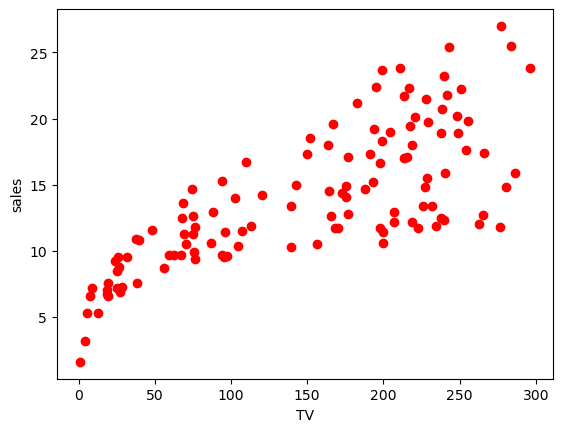

In [252]:
plt.scatter(x_train['TV'],y_train,color='red')
plt.xlabel("TV")
plt.ylabel("sales")
plt.plot()

In [254]:
#perfomance metrics forregression model

In [257]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [259]:
print(mean_absolute_error(y_test,y_pred))

1.2450232752628607


In [261]:
mean_squared_error(y_test,y_pred)

2.3915030342674846

In [263]:
print(np.sqrt(mean_squared_error(y_test,y_pred)))

1.546448522993082


In [264]:
#creating dataframe

In [265]:
result=pd.DataFrame(columns=['Actual_sales','Predicted_sales'])
result['Actual_sales']=y_test
result['Predicted_sales']=y_pred

result=result.reset_index()
result.head()

,index,Actual_sales,Predicted_sales
0,40,16.6,16.238225
1,86,12.0,11.492904
2,139,20.7,19.424112
3,2,9.3,12.472991
4,153,19.0,18.134831


In [266]:
#r2 valuecalculation

In [271]:
r2=r2_score(y_test,y_pred)

In [273]:
r2

0.9149379649187803